## __[Learning objectives](#toc)__

By the end of this notebook, you should be able to:
- Understand logistic regression.
- Implement a logistic regression model using `sklearn`.

## __[Binary classification](#toc_)__

### __[Quantitative vs. qualitative variables](#toc_)__

In this course, we have explored a variety of ways which we can use to predict a response variable _Y_ when that response is quantitative, or numerical, in nature. The numerical variables we predict typically exist on a continuous scale, and we can therefore fit models such as a linear regression in which, for increasing values of X, there are appropriate increasing or decreasing values of Y. An example of linear regression is shown below.

<img src="https://raw.githubusercontent.com/Explore-AI/Pictures/master/sketch-linear-reg.png" alt="sketch-linear-reg" style="width: 400px;"/>

In some cases, however, the response variable (Y) in our dataset will not be continuous – it will be categorical (qualitative). In this case, the prediction task is known as _classification,_ because we are trying to _classify_ an observation into the correct category.

The simplest version of this scenario is known as _binary classification_. Binary refers to the fact that there are two categories. It is normally intuitive to encode the two classes in a binary classification task as zeroes and ones.

<img src="https://raw.githubusercontent.com/Explore-AI/Pictures/master/sketch-categorical-y.png" alt="sketch-categorical-y" style="width: 300px"/>

With our response variable encoded as zeroes and ones, we are able to plot some of the data points for a predictor variable X and see the peculiar problem we are faced with: the response values lie along two distinct horizontal lines. What's more, they only ever take on values of 0 and 1! Clearly no good for a linear regression, which is only ever monotonically increasing or decreasing.

Looking at the values for Y which lie along an example linear regression line, we can see that for very large X we will be getting values for Y which are greater than 1, and as X decreases we may even get negative Y values – far from the zeroes and ones we need.

<img src="https://raw.githubusercontent.com/Explore-AI/Pictures/master/sketch-linear-classification.png" alt="sketch-linear-classification" style="width: 450px;"/>

## __[Logistic Regression](#toc_)__

The solution to this problem is known as *logistic regression*; so called because it makes use of a common S-shaped curve known as the logistic function. This curve is commonly known as a _sigmoid_. It solves the problem for the following reasons:

- It squeezes the range of output values to exist only between 0 and 1.
- It has a point of inflection, which can be used to separate the feature space into two distinct areas (one for each class).
- It has shallow gradients at both its top and bottom, which can be mapped to zeroes or ones respectively with little ambiguity.

<img src="https://raw.githubusercontent.com/Explore-AI/Pictures/master/sketch-logistic-regression.png" alt="sketch-logistic-regression" style="width: 600px;"/>

The name is a little confusing because it contains the word _regression_. That's because we are effectively doing a linear regression, but then squeezing that linear regression vertically down into the S-shape sigmoid curve, so that it exists between 0 and 1. Rest assured – this is definitely a **classification model**.

## __[Logistic Function]()__

We now know that the output value of a logistic regression model refers to the probability that the observation in question belongs to class 1. The output values all fall between 0 and 1, which is all very well. But at what threshold value do we decide that a probability is too low to be assigned to class 1? Usually, we pick 0.5. That is:

- Values greater than or equal to 0.5 are assigned to class 1.
- Values less than 0.5 are assigned to class 0.

This output needs to hold for all values of X. In other words, regardless of the value of X, we need the output to be a value between 0 and 1. The function that takes care of all this is defined as follows:

$$P(X) = \displaystyle \frac{e^{\beta_0 + \beta_1 X}}{1+e^{\beta_0 + \beta_1 X}}$$

where $P(X)$ is the probability of X belonging to class 1, and $\beta_0$ and $\beta_1$ are the intercept and regression coefficient respectively, just like in a linear regression model. After a bit of manipulation, we arrive at:

\begin{align}
1 - P(X) &= \displaystyle \frac{1}{1+e^{\beta_0 + \beta_1 X}} \\
\therefore \log \left( \frac{P(X)}{1-P(X)} \right) &= {\beta_0 + \beta_1 X}
\end{align}

The term on the left is known as the **log odds ratio**. Without the log sign in front of it, it is known simply as the odds ratio. While $P(X)$ is bounded between 0 and 1, the odds ratio is bounded between 0 and $\infty$.

_Note: If you're still having trouble understanding the concept of log odds ratios, please see the videos in the additional resources section._

### __[Multi-class classification](#toc_)__

There will clearly be cases when we have more than two categories in our labels column. Perhaps we are classifying the colour of cars into one of: `[red, green, blue]`.

As we have seen, the logistic regression algorithm is effective for those situations with no more than two classes. There is, however, a neat way to combine logistic regression models for multi-class classification in what is known as the one-vs-rest approach (or OvR).

In the OvR case, a separate logistic regression model is trained for each label that the response variable takes on.

<img src="https://raw.githubusercontent.com/Explore-AI/Pictures/master/sketch-one-vs-rest.png" alt="sketch-one-vs-rest" style="width: 600px;"/>

Fortunately, `sklearn` makes it very simple to implement this multi-class extension of the logistic regression algorithm. We'll include a note on it in this notebook and the actual code for it later on in the course.

### __[Non-linearly separable data points](#toc_)__

One last thing to note here before we move on to implementation. Logistic regression models are effective only for those cases in which we have clearly linearly separable data. That is to say a straight line or hyperplane can be placed somewhere among the data points that definitively separate them.

<img src="https://raw.githubusercontent.com/Explore-AI/Pictures/master/sketch-non-separable.png" alt="sketch-non-separable" style="width: 600px;"/>

In those cases where our data are not linearly separable, we will need to try out other algorithms (perhaps linear discriminant analysis or a support vector classifier). We will explore many more models to carry out more complex classification tasks in this course. Stay tuned!

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [22]:
df = pd.read_csv("../data/claims_data.csv")
display(df.head())

,age,sex,bmi,steps,children,smoker,region,insurance_claim,claim_amount
0,19,female,27.900,3009,0,yes,southwest,yes,16884.9240
1,18,male,33.770,3008,1,no,southeast,yes,1725.5523
2,28,male,33.000,3009,3,no,southeast,no,0.0000
3,33,male,22.705,10009,0,no,northwest,no,0.0000
4,32,male,28.880,8010,0,no,northwest,yes,3866.8552


In [23]:
# check the data types of the columns
for col in df.columns:
    print(f"{col:>15}: {df[col].dtype}")

            age: int64
            sex: str
            bmi: float64
          steps: int64
       children: int64
         smoker: str
         region: str
insurance_claim: str
   claim_amount: float64


### __[Data Preprocessing](#toc_)__

In [24]:
from sklearn.model_selection import train_test_split

In [25]:
y = df['insurance_claim']
X = df.drop(columns=['insurance_claim'])

In [26]:
X_transformed = pd.get_dummies(X, drop_first=True)

In [27]:
X_train, X_test, y_train, y_test = train_test_split(
    X_transformed, 
    y, test_size=0.2,
      random_state=42
)

### __[Data Training](#toc_)__


In [28]:
from sklearn.linear_model import LogisticRegression

In [29]:
logreg = LogisticRegression(random_state=42, max_iter=1000)

We use the `fit()` method to train the model.

**Pro tip**: In the multi-class case we referred to above, the `LogisticRegression` instance takes a simple argument which enables it to be used for 2+ classes: `multi_class='ovr'`. We'll revisit this later in the course.

In [30]:
logreg.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lb

#### **[Intercept](#toc_)**

The interpretation of the parameters of the logistic model is not quite the same as for a linear regression model.

In binary classification, the class with value 1 is known as the _reference class_. Let's explore.

The intercept, $\beta_0$, is interpreted as the **log odds** ratio of an observation being in the reference class when all other predictor variables are equal to zero.

We can exponentiate this value, i.e. raise the natural number $e$ to this value to convert it to a typical **odds** ratio. In other words:

$$Odds = e^{\beta_0}$$

In [31]:
# Print the intercept
print("Intercept:", logreg.intercept_[0])


Intercept: -6.850442546725569e-07


#### **[Coefficients](#toc_)**

For binary categorical variables, like `smoker` and `sex`, the coefficient is interpreted as the **log odds** ratio between the class implied by a zero for the variable (i.e. non-smoker), and the class implied by a one for the variable (i.e. smoker).

For continuous variables, the coefficient is interpreted as the expected change in the log odds for a one-unit increase in the variable.

Again, we can arrive at the usual odds value by exponentiating the coefficient:

$$Odds = e^{\beta_1}$$

Effectively, each coefficient is a measure of the change in the log odds of belonging to the reference class for one-unit changes in the variable.

In [32]:
# Get the coefficients as a DataFrame
coefficients = pd.DataFrame({
    "Feature": X_transformed.columns,
    "Coefficient": logreg.coef_[0]
})

# Sort coefficients from highest to lowest
coefficients = coefficients.sort_values(
    by="Coefficient",
    ascending=False
)

display(coefficients)

,Feature,Coefficient
4,claim_amount,1.007761e-01
6,smoker_yes,1.389605e-06
8,region_southeast,3.404806e-07
5,sex_male,-7.384619e-08
9,region_southwest,-3.034951e-07
7,region_northwest,-6.641939e-07
1,bmi,-3.771730e-06
3,children,-9.789807e-06
0,age,-1.028113e-05
2,steps,-8.958590e-03


In [33]:
from plot import style_plot

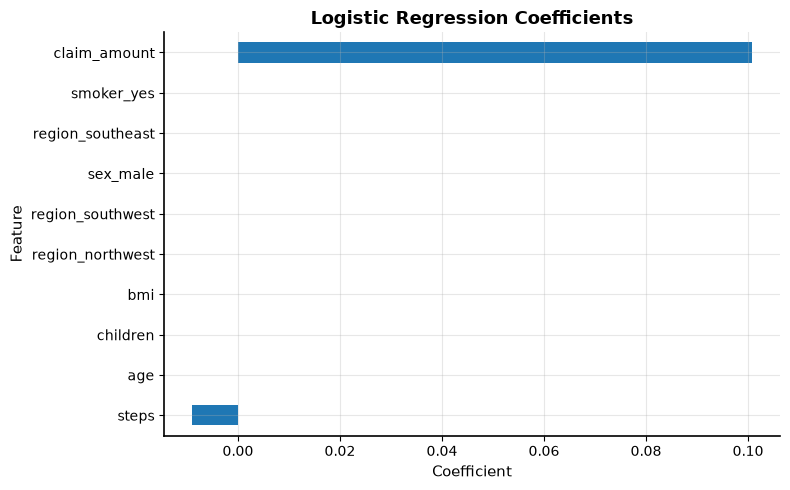

In [34]:
fig, ax = plt.subplots(figsize=(8, 5))

coefficients.sort_values("Coefficient").plot(
    x="Feature",
    y="Coefficient",
    kind="barh",
    ax=ax,
    legend=False
)

style_plot(
    ax,
    title="Logistic Regression Coefficients",
    xlabel="Coefficient",
    ylabel="Feature"
)

plt.tight_layout()
plt.show()

### **[Prediction](#toc_)**

In [35]:
# Prediction time
y_pred = logreg.predict(X_test)

### **[Model Evaluation](#toc_)**

In [36]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [37]:
# Evaluate the logistic regression model

metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score"],
    "Logistic Regression": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, pos_label="yes"),
        recall_score(y_test, y_pred, pos_label="yes"),
        f1_score(y_test, y_pred, pos_label="yes")
    ]
})

# Round the results
metrics["Logistic Regression"] = (
    metrics["Logistic Regression"].round(4)
)

display(metrics)

,Metric,Logistic Regression
0,Accuracy,1.0
1,Precision,1.0
2,Recall,1.0
3,F1-Score,1.0


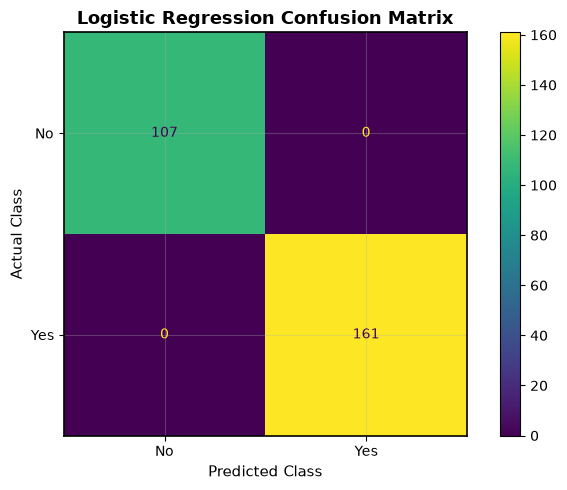

In [38]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["no", "yes"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No", "Yes"]
)

fig, ax = plt.subplots(figsize=(7, 5))

disp.plot(
    ax=ax,
    values_format="d"
)

style_plot(
    ax,
    title="Logistic Regression Confusion Matrix",
    xlabel="Predicted Class",
    ylabel="Actual Class",
    remove_spine=False
)

plt.tight_layout()
plt.show()

- The model achieved 100% accuracy, precision, recall, and F1-score on this test set. In business terms, it could support highly accurate claim-risk identification and help insurers allocate resources efficiently.

- However, perfect performance is unusual and should be validated on additional data to rule out data leakage or an unrepresentatively easy test sample.

#### __Quiz__

<br>1.

> A developer uses scikit-learn to analyze an airport security screening model. The confusion matrix contains: TP = 80, FN = 20, FP = 10, and TN = 890. The developer wants to evaluate Recall to see what percentage of actual security threats the model successfully caught. What is the calculated Recall value?

__[Solution]()__

$$\text Recall = \frac{TP}{TP+TN}$$
$$= \frac{80}{80+20}$$
$$= 0.8$$
$$\boxed{\text{Precision} = 80\%}$$

<br>2.

> Consider the following confusion matrix generated from a binary classification model predicting credit card fraud (where "Fraud" is the positive class and "Legitimate" is the negative class):
- Actual Fraud, Predicted Fraud: 45
- Actual Fraud, Predicted Legitimate: 15
- Actual Legitimate, Predicted Fraud: 30
- Actual Legitimate, Predicted Legitimate: 910

Which of the following correctly maps these values to their corresponding classification counts?

__[Answer]()__

> **True Positives = 45, False Negatives = 15, False Positives = 30, True Negatives = 910**

<br>3.

> An email provider is tuning a spam filter. If a legitimate email is flagged as spam (a False Positive), a user might miss a critical message from their employer. If a spam email gets through to the inbox (a False Negative), it is merely a minor annoyance. Which classification metric should the engineering team maximize to ensure they minimize costly False Positives?

__[Answer]()__

- **Precision**

<br>4.

> A data scientist trains a logistic regression model to detect a rare disease that occurs in only 0.5% of the population. The model simply predicts "Negative" (no disease) for every single patient. The overall accuracy of this model is 99.5%. Why is accuracy a misleading measure of performance in this scenario?

__[Answer]()__

> Accuracy hides the fact that the model has a `0%` success rate at detecting the actual target class (the disease), failing entirely at its intended purpose despite the high score.


<br>5

> A machine learning model yields the following classification report metrics for the positive class:
- Precision: 0.40
- Recall: 0.90
What is the correct F1-score for this class, and what does this specific score tell you about the balance between the metrics?

__[Answer]()__

> `F1-score = 0.55`; calculated as the `harmonic mean`, it indicates an `imbalance` where high recall is being heavily penalized by poor precision


<br>6.

> A developer is tuning a classification model in scikit-learn. They want to systematically search for the best combinations of parameters that control the model's training behavior, such as the regularization strength parameter C and the penalty type (e.g., 'l1' vs 'l2'). What are these configuration parameters called, and what role do they play in the cycle of refinement?

__[Answer]()__

> They are hyperparameters, which are external settings configured by the developer before training to control the complexity of the learning process and prevent overfitting.

<br>7.

> A medical diagnostics company is working with a highly imbalanced dataset where only 1% of patients test positive for a genetic marker. They plan to use resampling strategies before training their logistic regression model. Which description accurately identifies these techniques and states when they are appropriate?

__[Answer]()__

> Oversampling increases minority class representation (e.g., synthetically duplicating rows), which is ideal when data is sparse; undersampling decreases majority class representation, which helps reduce training time on massive datasets but risks throwing away valuable information.


<br>8.

> An engineering team is refining a credit card fraud detection classifier. Currently, the model flags an account as fraudulent if its internal probability output is greater than or equal to 0.50. Because the financial cost of missing an actual fraud case (a False Negative) is incredibly high, they decide to systematically lower the model's decision threshold to 0.25. What is the direct impact of this operational change?

__[Answer]()__

> It increases recall and decreases precision, meaning the model will successfully capture more actual fraud cases at the expense of creating more false alarms (False Positives).

<br>9.

> A machine learning engineer wants to implement a repeatable, systematic model improvement workflow. They have a dataset containing thousands of text-extracted features, but many carry almost no predictive signal or are highly redundant. Why can reducing the feature set actively improve classification performance, rather than just simplifying the code?

__[Answer]()__

> Minimizing features eliminates noise, mitigates multicollinearity, and reduces the risk of overfitting, allowing algorithms like logistic regression to find more stable, generalizable decision boundaries.

<br>10.

> A data scientist trains a multi-class logistic regression model on the MBTI personality dataset to predict personality profiles. Upon reviewing the output, they notice that common personality types have a 92% F1-score, while rare personality types (such as INFJ) have a 12% F1-score. Why does a skewed class distribution make overall global accuracy a misleading metric for evaluating this model's performance?

__[Answer]()__

> Accuracy hides poor performance on underrepresented minority classes because the score is mathematically dominated by the model's success on the highly populated majority classes.





__[Note]()__


### 1. **True Positive (TP)**

The model **correctly predicts the positive class**.

**Example:** Fraudulent transaction correctly identified as fraud.

---

### 2. **True Negative (TN)**

The model **correctly predicts the negative class**.

**Example:** Legitimate transaction correctly identified as legitimate.

---

### 3. **False Positive (FP)**

The model predicts **positive**, but the actual class is **negative**.

**Example:** Legitimate transaction incorrectly classified as fraud.

Also called a **Type I error**.

---

### 4. **False Negative (FN)**

The model predicts **negative**, but the actual class is **positive**.

**Example:** Fraudulent transaction incorrectly classified as legitimate.

Also called a **Type II error**.

---

### 5. **Accuracy**

The proportion of **all predictions that are correct**.

$$
\boxed{\text{Accuracy}=\frac{TP+TN}{TP+TN+FP+FN}}
$$

**Use:** Overall correctness.

**Problem:** Can be misleading with **class imbalance**.

---

### 6. **Precision**

Of all observations predicted as **positive**, how many were actually positive?

$$
\boxed{\text{Precision}=\frac{TP}{TP+FP}}
$$

**Question to remember:**

> *When the model predicts positive, how often is it correct?*

High precision → **few false positives**.

---

### 7. **Recall**

Of all observations that are **actually positive**, how many did the model correctly identify?

$$
\boxed{\text{Recall}=\frac{TP}{TP+FN}}
$$

Also called **Sensitivity** or **True Positive Rate (TPR)**.

**Question to remember:**

> *Of all actual positives, how many did the model find?*

High recall → **few false negatives**.

---

### 8. **F1 Score**

The **harmonic mean of precision and recall**.

$$
\boxed{
F1=2\times\frac{\text{Precision}\times\text{Recall}}
{\text{Precision}+\text{Recall}}
}
$$

**Use:** Balances precision and recall, especially when classes are imbalanced.

A high F1 requires **both precision and recall to be reasonably high**.

---

### 9. **Support**

The number of **actual observations in each class**.

There is no formula:

$$
\boxed{\text{Support} = TP + FN}
$$

for the positive class, and

$$
\boxed{\text{Support} = TN + FP}
$$

for the negative class.

---

### 10. **Confusion Matrix**

A table summarizing the four possible classification outcomes:

| Actual / Predicted | Negative (0) | Positive (1) |
| ------------------ | -----------: | -----------: |
| **Negative (0)**   |           TN |           FP |
| **Positive (1)**   |           FN |           TP |

It is the foundation for calculating **accuracy, precision, recall, and F1 score**.

---

### 11. **Positive Class**

The class we are primarily interested in detecting.

Usually represented as **1**.

**Example:** In fraud detection, `1 = fraudulent`.

---

### 12. **Negative Class**

The class that is not the primary class of interest.

Usually represented as **0**.

**Example:** In fraud detection, `0 = legitimate`.

---

### 13. **Class Imbalance**

When one class contains **significantly more observations** than another.

Example:

```text
Legitimate: 9,900
Fraud:       100
```

A model predicting everything as legitimate gets **99% accuracy**, but detects **zero fraud**.

---

### 14. **Macro Average**

Calculates the metric for each class and then gives **equal weight to every class**.

For two classes:

$$
\boxed{
\text{Macro F1}=
\frac{F1_0+F1_1}{2}
}
$$

Useful when you want **both classes to matter equally**, regardless of their sizes.

---

### 15. **Weighted Average**

Calculates the metric for each class but weights each class according to its **support**.

$$
\boxed{
\text{Weighted Metric}
=
\frac{\sum(\text{Metric}_i\times\text{Support}_i)}
{\sum\text{Support}_i}
}
$$

Useful when you want the metric to reflect the **actual class distribution**.

---

### **Quick memory guide**

| Metric           | Main question                                     |
| ---------------- | ------------------------------------------------- |
| **Accuracy**     | How often is the model correct overall?           |
| **Precision**    | When it predicts positive, is it correct?         |
| **Recall**       | Did it find the actual positives?                 |
| **F1**           | How well does it balance precision and recall?    |
| **Support**      | How many actual examples are in each class?       |
| **Macro avg**    | How well does it perform across classes equally?  |
| **Weighted avg** | How well does it perform considering class sizes? |

**Most important distinction:**

> **Precision focuses on false positives (FP), while recall focuses on false negatives (FN).**


Here is the concise **study-note version** of this section, with the important formulas.

### 1. **Logistic Regression**

Despite its name, **logistic regression is a classification algorithm**. It predicts the probability that an observation belongs to the positive class.

$$
P(y=1|X)=\frac{1}{1+e^{-(\beta_0+\beta_1x_1+\cdots+\beta_nx_n)}}
$$

The output is between **0 and 1**.

---

### 2. **Probability Threshold**

The default threshold in scikit-learn is **0.5**.

$$
\hat y =
\begin{cases}
1, & P(y=1|X)\geq0.5\\
0, & P(y=1|X)<0.5
\end{cases}
$$

Changing the threshold changes the number of positive predictions.

---

### 3. **Linear Decision Boundary**

Logistic regression creates a **linear decision boundary**.

For two features:

$$
\beta_0+\beta_1x_1+\beta_2x_2=0
$$

The boundary separates the two classes.

---

### 4. **`predict_proba()`**

Returns the predicted probability for **each class**.

```python
y_pred_probs = logisticRegr.predict_proba(X_test)
```

For binary classification:

```text
Column 0 → P(class 0)
Column 1 → P(class 1)
```

To get the positive-class probability:

```python
y_pred_probs = logisticRegr.predict_proba(X_test)[:, 1]
```

---

### 5. **ROC Curve**

**ROC = Receiver Operating Characteristic**

It shows how the classifier's performance changes as the **probability threshold changes**.

It plots:

* **X-axis:** False Positive Rate (FPR)
* **Y-axis:** True Positive Rate (TPR)

---

### 6. **True Positive Rate (TPR)**

TPR is another name for **Recall/Sensitivity**.

$$
\boxed{TPR=\frac{TP}{TP+FN}}
$$

It measures the proportion of actual positives correctly identified.

---

### 7. **False Positive Rate (FPR)**

Measures the proportion of actual negatives incorrectly classified as positive.

$$
\boxed{FPR=\frac{FP}{FP+TN}}
$$

A lower FPR is better.

---

### 8. **ROC Thresholds**

As the classification threshold changes:

* **Threshold ↓** → more positive predictions → usually **TPR ↑ and FPR ↑**
* **Threshold ↑** → fewer positive predictions → usually **TPR ↓ and FPR ↓**

At threshold **0**, almost everything is predicted as positive.

At threshold **1**, almost everything is predicted as negative.

---

### 9. **ROC-AUC**

**AUC = Area Under the ROC Curve**

It summarizes the ROC curve into a single number between **0 and 1**.

$$
\boxed{AUC=\text{Area under the ROC curve}}
$$

Interpretation:

|         AUC | Interpretation     |
| ----------: | ------------------ |
|     **1.0** | Perfect classifier |
| **0.9–1.0** | Excellent          |
| **0.8–0.9** | Very good          |
| **0.7–0.8** | Good               |
|     **0.5** | Random guessing    |
|   **< 0.5** | Worse than random  |

A higher AUC means the model is generally **better at distinguishing between the positive and negative classes across different thresholds**.

---

### 10. **Chance Line**

The diagonal ROC line represents **random guessing**.

$$
TPR = FPR
$$

Its AUC is:

$$
\boxed{AUC=0.5}
$$

A good classifier should have its ROC curve **above this line**.

---

### **Important distinction**

**F1** evaluates performance at a **specific classification threshold**.

**ROC-AUC** evaluates how well the model separates the classes **across many possible thresholds**.

And when calculating ROC-AUC, use **probabilities**, not hard predictions:

```python
y_pred_probs = logisticRegr.predict_proba(X_test)[:, 1]

roc_auc = roc_auc_score(y_test, y_pred_probs)
```

Not:

```python
roc_auc_score(y_test, logisticRegr.predict(X_test))
```

That distinction is especially important for your current Logistic Regression/SVM work.
